# 02 · What each angular order can resolve

Construct exact collisions at lower orders. Balanced horizontal and vertical axes have equal zero means and different Q-tensors. Four cardinal directions and four diagonal directions have both equal zero means and equal zero Q, yet different fourth angular moments.

## Setup
All examples use synthetic configurations. See THEORY.md for definitions, assumptions and proofs.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import *
from observables.patterns import *
from observables.images import *
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,3.5),'figure.dpi':110,
                    'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
def unit_circle(angles):
    return np.column_stack([np.cos(angles),np.sin(angles)])
SEED=41

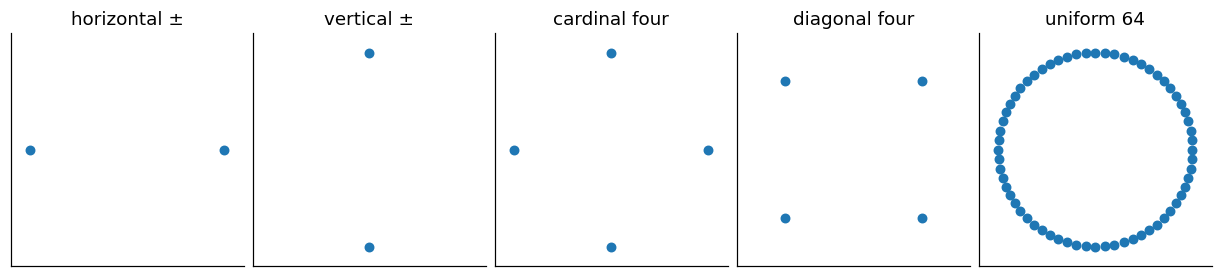

,configuration,mean norm,Q norm,|m1|,|m2|,|m4|
0,horizontal ±,0.0,0.70711,0.0,1.0,1.0
1,vertical ±,0.0,0.70711,0.0,1.0,1.0
2,cardinal four,0.0,0.00000,0.0,0.0,1.0
3,diagonal four,0.0,0.00000,0.0,0.0,1.0
4,uniform 64,0.0,0.00000,0.0,0.0,0.0


In [3]:
configs={'horizontal ±':unit_circle([0,np.pi]),'vertical ±':unit_circle([np.pi/2,3*np.pi/2]),
         'cardinal four':unit_circle(np.arange(4)*np.pi/2),
         'diagonal four':unit_circle(np.arange(4)*np.pi/2+np.pi/4),
         'uniform 64':unit_circle(np.arange(64)*2*np.pi/64)}
fig,axes=plt.subplots(1,5,figsize=(11,2.6))
rows=[]
for ax,(name,u) in zip(axes,configs.items()):
    ax.scatter(u[:,0],u[:,1],s=30)
    ax.set(xlim=(-1.2,1.2),ylim=(-1.2,1.2),aspect='equal',title=name,xticks=[],yticks=[])
    m,q=moments(u);z=circular_moments(np.arctan2(u[:,1],u[:,0]))
    rows.append((name,np.linalg.norm(m),np.linalg.norm(q),*np.abs(z)))
show('02_direction_configurations')
display(pd.DataFrame(rows,columns=['configuration','mean norm','Q norm','|m1|','|m2|','|m4|']).round(5))

In [5]:
pairs=[('horizontal ±','vertical ±'),('cardinal four','diagonal four'),('cardinal four','uniform 64')]
table=[]
for a,b in pairs:
    table.append((a+' vs '+b,*[angular_distance(configs[a],configs[b],k) for k in (1,2,4)]))
frame=pd.DataFrame(table,columns=['pair','D1 squared','D2 squared','D4 squared'])
display(frame.round(6));frame.to_csv(OUT/'moment_collisions.csv',index=False)
assert np.allclose(frame.iloc[1,1:3].astype(float),0,atol=1e-12)
assert np.isclose(frame.iloc[1,3],4)

,pair,D1 squared,D2 squared,D4 squared
0,horizontal ± vs vertical ±,0.0,4.0,0.0
1,cardinal four vs diagonal four,0.0,0.0,4.0
2,cardinal four vs uniform 64,0.0,0.0,1.0


## A continuous transition between polar and nematic order
For $P(u=+e_x)=p$ and $P(u=-e_x)=1-p$, the mean is $(2p-1)e_x$. Q is independent of p. Odd order changes sign under reversing all directions, while even order is invariant.

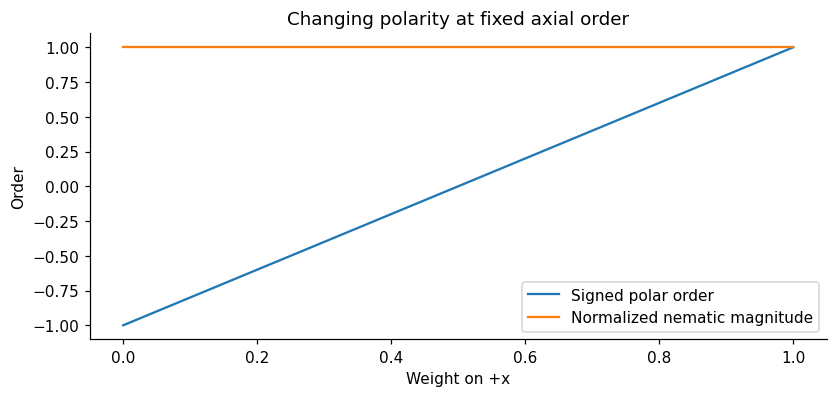

In [7]:
weights=np.linspace(0,1,101);polar=[];nematic=[]
u=np.array([[1.,0.],[-1.,0.]])
for p in weights:
    m,q=moments(u,[p,1-p]);polar.append(m[0]);nematic.append(np.sqrt(2)*np.linalg.norm(q))
plt.plot(weights,polar,label='Signed polar order');plt.plot(weights,nematic,label='Normalized nematic magnitude')
plt.xlabel('Weight on +x');plt.ylabel('Order');plt.title('Changing polarity at fixed axial order')
plt.legend();show('02_polar_nematic')

## Resolving power and failure
Zero Q does not establish isotropy. The cardinal and diagonal configurations give exact counterexamples. Every finite hierarchy has possible collisions. These examples certify specific distinctions; increasing order does not guarantee better task performance or better statistical estimation.